# 04 · Ensembles, Kenya → Ghana transfer, and the fairness audit

**Owner:** Eugene (P4). **Issues:** #54 (this notebook), #18 (RF, LightGBM), #23 and #24 (Part C), #26 and #50 (Part D), #28 (Findex).

This notebook audits the model that actually ships: **logistic regression, Platt-calibrated**, decision threshold from the cedi cost matrix in `configs/cost_matrix.yaml` (D-26), and a starter loan for first-time borrowers just above it (D-24). It is saved as `artifacts/task2_clf.joblib` by `make artifacts`. Everything here runs on the shared pipeline in `src/`. The only logic defined in this notebook is the cost of the mitigation options in section 3.4.

**What changed from the PR #46 draft.** The draft had four known problems, and all four are fixed:
1. Every threshold is now applied to **calibrated** probabilities (`calibrate_oof`, Platt, as deployed).
2. The mitigation now shows its **cost in money**, next to how many more people it approves (§3.4).
3. A **proxy analysis** has been added (§3.3).
4. The Model Card, Datasheet, regulatory map and decline message are written up in `docs/audit/`.

Run `make features artifacts` first. The first section trains 3 models × 2 schemes, which takes about a minute.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.analysis.data_profile import findex_access
from src.evaluation import (
    add_loan_size_band,
    calibrate_oof,
    classification_metrics,
    cost_matrix_threshold,
    decision_cost_by_group,
    disaggregated_evaluation,
    load_cost_config,
    proxy_strength,
    run_domain_classifier,
)
from src.processing import load_features
from src.serving import decide, score_frame
from src.training import run_cv
from src.visualization import (
    plot_domain_scores,
    plot_feature_shift,
    plot_group_selection_rates,
    plot_reliability,
    plot_shift_drivers,
)

pd.set_option("display.width", 160)
df = load_features()
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

cost = cost_matrix_threshold()                  # shipped: cedis, configs/cost_matrix.yaml (D-26)
THR = cost["threshold"]
STARTER = load_cost_config()["starter_loan"]    # first-time borrowers just above THR get a starter loan (D-24)
# Earlier cost matrices, kept as sensitivities
THR_KES = cost_matrix_threshold(principal=5249, fee_rate=0.0168, collection_cost=250, future_loans=1)["threshold"]  # D-19
THR_1LOAN = cost_matrix_threshold(future_loans=1)["threshold"]   # D-22: cedis, only this loan lost
THR_6LOANS = cost_matrix_threshold(future_loans=6)["threshold"]
print(f"Shipped threshold {THR:.4f}  (C_FP {cost['c_fp']:.0f} GHS, C_FN {cost['c_fn']:.0f} GHS); starter loan {STARTER}")
print(f"Sensitivities: KES (D-19) {THR_KES:.4f} · cedis, 1 loan lost {THR_1LOAN:.4f} · cedis, 6 loans lost {THR_6LOANS:.4f}")

Shipped threshold 0.1006  (C_FP 270 GHS, C_FN 2416 GHS); starter loan {'max_probability': 0.3, 'share_of_request': 0.25}
Sensitivities: KES (D-19) 0.0194 · cedis, 1 loan lost 0.0359 · cedis, 6 loans lost 0.1828


## 1. Random Forest and LightGBM against the shipped logistic regression (#18)

All three models use the same features (D-18: no macro columns, and a single amount column in USD). Each is scored twice: by customer (`fold_group`, the split we use to compare models, D-7) and by time (`temporal`, the honest forecast).

In [2]:
models = ["logreg", "random_forest", "lightgbm"]
oof, rows = {}, []
for m in models:
    for scheme in ["fold_group", "temporal"]:
        p = run_cv(df, model_name=m, task="task2", scheme=scheme, save_preds=False)
        r = classification_metrics(p["y_true"], p["y_pred"], threshold=THR)
        rows.append({"model": m, "scheme": scheme, "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"]})
        if scheme == "fold_group":
            oof[m] = p.assign(y_cal=calibrate_oof(p["y_true"], p["y_pred"], p["fold"], method="platt"))
ranking = pd.DataFrame(rows).pivot(index="model", columns="scheme", values=["roc_auc", "pr_auc"]).round(3)
ranking

roc_auc              pr_auc         
scheme        fold_group temporal fold_group temporal
model                                                
lightgbm           0.849    0.582      0.195    0.148
logreg             0.843    0.633      0.176    0.134
random_forest      0.871    0.618      0.203    0.156

**Reading.** By customer, Random Forest ranks defaulters best (PR-AUC 0.203), LightGBM comes second (0.195) and logistic regression third (0.176). The base rate is 0.018, so all three are roughly ten times better than guessing. By time, every model falls to a ROC-AUC of about 0.6, and the order changes. The ensembles' advantage is small, and it does not hold up for future loans. That is why shipping the logistic regression costs little in accuracy, and the credit committee gets a model it can explain coefficient by coefficient.

**How the two ensembles differ.** Random Forest uses *bagging*. It averages many deep trees, each grown on a bootstrap sample with a random subset of features, and the averaging lowers variance. LightGBM uses *boosting*. It adds shallow trees one at a time, each fitted to the gradient of the log-loss of the model built so far, and this lowers bias. The derivation is in `docs/derivations/boosting.md`, and the settings are in `configs/models.yaml`.

### 1.1 Calibrate before any threshold (fixes draft problem 1)

Class weights (`balanced`, `scale_pos_weight`) tell the model that defaults matter about 54 times more than repayments. That improves ranking, but it pushes every probability up. The deployment bundle therefore applies Platt scaling, which is fitted out of fold. The table below reads approval rates off raw scores and off calibrated scores.

,model,true_default_rate,mean_raw,mean_calibrated,approved_raw,approved_calibrated,approved_at_KES_0.019,recall,precision
0,logreg,0.018,0.322,0.018,0.145,0.975,0.828,0.262,0.192
1,random_forest,0.018,0.258,0.018,0.313,0.965,0.810,0.369,0.192
2,lightgbm,0.018,0.150,0.018,0.626,0.970,0.741,0.326,0.200


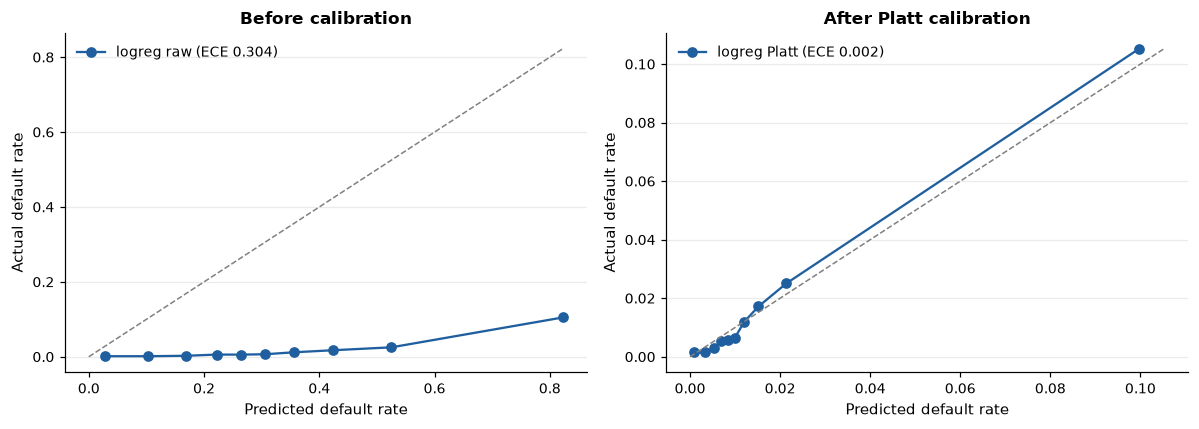

In [3]:
cal_rows = []
for m, p in oof.items():
    r = classification_metrics(p["y_true"], p["y_cal"], threshold=THR)
    cal_rows.append({
        "model": m,
        "true_default_rate": p["y_true"].mean(),
        "mean_raw": p["y_pred"].mean(),
        "mean_calibrated": p["y_cal"].mean(),
        "approved_raw": np.mean(p["y_pred"] <= THR),
        "approved_calibrated": np.mean(p["y_cal"] <= THR),
        f"approved_at_KES_{THR_KES:.3f}": np.mean(p["y_cal"] <= THR_KES),
        "recall": r["recall"],
        "precision": r["precision"],
    })
display(pd.DataFrame(cal_rows).round(3))

lr = oof["logreg"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_reliability(lr["y_true"], {"logreg raw": lr["y_pred"].to_numpy()}, ax=axes[0])
axes[0].set_title("Before calibration")
plot_reliability(lr["y_true"], {"logreg Platt": lr["y_cal"].to_numpy()}, ax=axes[1])
axes[1].set_title("After Platt calibration")
plt.tight_layout()
plt.show()

**Reading.** The raw logistic scores average 0.32, against a true default rate of 0.018. If you apply the shipped threshold (0.10) to them, only 14.5% of applicants are approved. The draft's fairness tables were read off raw scores like these, so they were badly wrong.

After calibration the mean prediction equals the base rate, and the model approves 97.5% of Kenyan applicants. It catches 26% of defaulters, and about one decline in five is a true defaulter. Under the old KES cost matrix (threshold 0.019) it approved 83%.

Calibration does not change the ranking (PR-AUC is unchanged), so from here on every rate, threshold and cost uses calibrated probabilities.

## 2. Part C: does a model trained on Kenya transfer to Ghana? (#23, #24)

### 2.1 How different are Ghana's applications?

rows  median_amount_usd  mean_duration_days  new_borrower_share  median_past_loans  mean_past_labelled  mean_inflation
split country_id                                                                                                                         
test  Ghana        3525            494.399              35.938               0.018                5.0               0.000          12.718
      Kenya       15069             46.188               8.289               0.007                9.0              11.087           6.197
train Kenya       68654             47.411               8.545               0.008                9.0              11.050           6.203

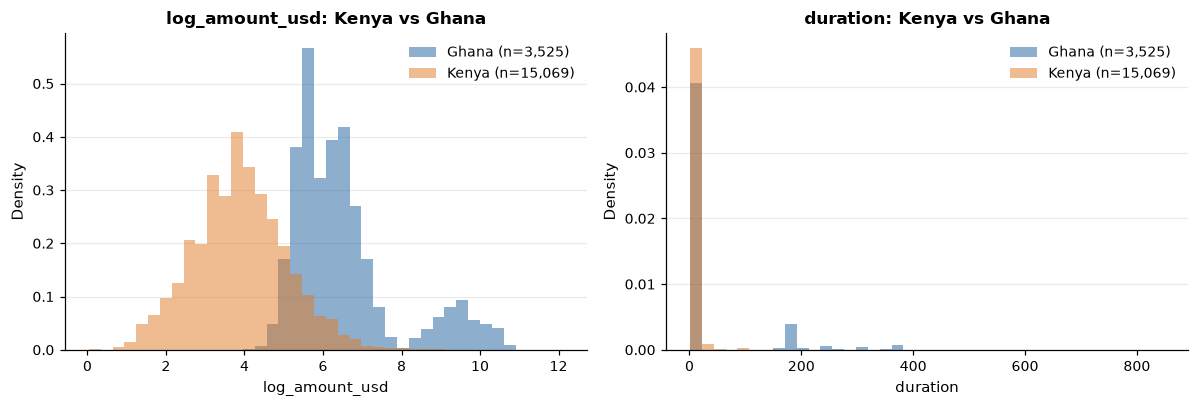

In [4]:
summary = (
    df.assign(amount_usd=np.expm1(df["log_amount_usd"]))
    .groupby(["split", "country_id"])
    .agg(rows=("ID", "count"), median_amount_usd=("amount_usd", "median"), mean_duration_days=("duration", "mean"),
         new_borrower_share=("is_new_borrower", "mean"), median_past_loans=("n_past_loans", "median"),
         mean_past_labelled=("n_past_labelled", "mean"), mean_inflation=("macro_inflation", "mean"))
    .round(3)
)
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_feature_shift(test, "log_amount_usd", ax=axes[0])
plot_feature_shift(test, "duration", ax=axes[1])
plt.tight_layout()
plt.show()

**Reading.** The median Ghanaian loan is about USD 494, roughly ten times the Kenyan median of USD 46–47. Ghanaian loans also run about four times longer (36 days against 8). Two further gaps are not about borrower behaviour:
- **Label history is structurally zero in Ghana.** `n_past_labelled` and the past-default features count earlier loans with a *known outcome*. Labels exist only in `Train.csv`, and Train is all Kenyan, so every Ghanaian row has a labelled history of 0. A Ghanaian with five earlier loans looks, to the model, like someone whose loans have not yet come due. That is a property of the data files, not of the borrowers.
- **The macro gap.** Ghana's previous-year inflation averages 12.7% in these rows, against 6.2% for Kenya, and it reached 31% in 2022. Since D-18 the macro columns are no longer model inputs, so this matters here only for the shift study.

### 2.2 Domain classifier: can a model tell Kenya from Ghana?

If the domain classifier cannot separate the two countries (AUC ≈ 0.5), Kenyan validation results carry over to Ghana. If it can (AUC ≈ 1), Ghana's scores are extrapolation. I run it on five feature sets, so we can see *what* separates the countries. The **effective sample share** (ESS / n) of the importance weights shows whether reweighting Kenyan validation to look like Ghana is workable: near 1 is fine, near 0 means a handful of Kenyan rows would carry the whole estimate.

,features,domain_roc_auc,effective_sample_share,top_drivers
0,model features (D-18),0.9969,0.0221,"n_past_labelled, n_past_loans, log_amount_usd"
1,minus label history,0.9852,0.0418,"log_amount_usd, n_past_loans, n_lenders_on_loan"
2,minus label history and amount,0.9584,0.0749,"n_lenders_on_loan, disb_month, Lender_portion_..."
3,plus lender and loan type,1.0000,0.3398,"loan_type_Type_3, lender_id_267278, lender_id_..."
4,plus macro columns,1.0000,1.0000,"macro_fx, macro_unemployment, macro_deposit_rate"


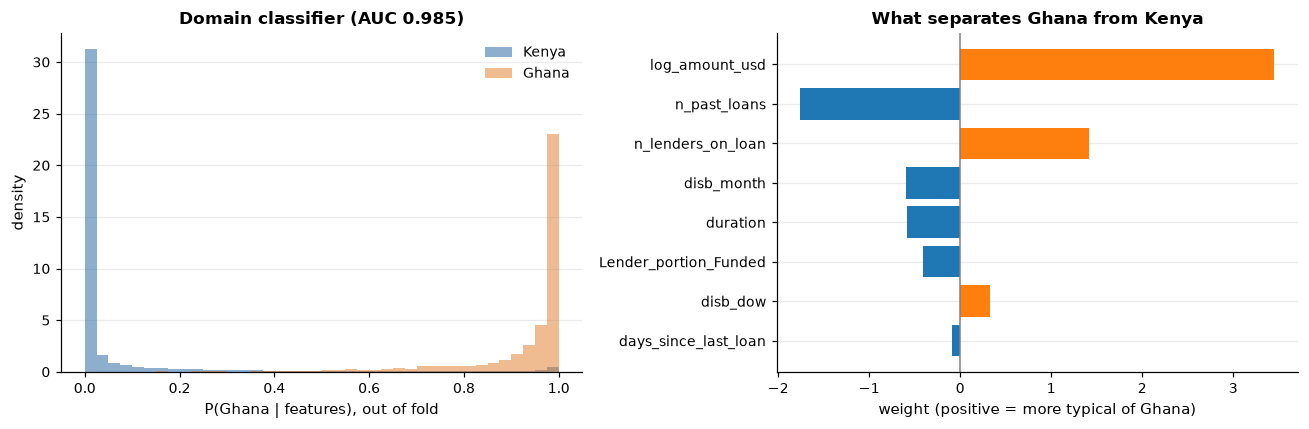

In [5]:
LABEL_HISTORY = ("n_past_labelled", "n_past_defaults", "past_default_rate", "days_since_last_default")
variants = {
    "model features (D-18)": {},
    "minus label history": {"drop_cols": LABEL_HISTORY},
    "minus label history and amount": {"drop_cols": LABEL_HISTORY + ("log_amount_usd",)},
    "plus lender and loan type": {"include_categoricals": True},
    "plus macro columns": {"include_macro": True},
}
dom = {name: run_domain_classifier(df, **kw) for name, kw in variants.items()}
display(pd.DataFrame([
    {"features": name, "domain_roc_auc": d["domain_roc_auc"], "effective_sample_share": d["effective_sample_share"],
     "top_drivers": ", ".join(d["top_shift_drivers"]["feature"].str.split("__").str[-1].head(3))}
    for name, d in dom.items()
]).round(4))

d = dom["minus label history"]
is_gh = df["country_id"].eq("Ghana").to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_domain_scores(d["oof_ghana_prob"], is_gh, d["domain_roc_auc"], ax=axes[0])
plot_shift_drivers(d["top_shift_drivers"], top=8, ax=axes[1])
plt.tight_layout()
plt.show()

**Reading.**
- On the model's own features the classifier separates the countries almost perfectly (AUC 0.997), and the top driver is `n_past_labelled`, the structural zero from §2.1.
- Removing the label-history fields lowers the AUC only to 0.985. The remaining drivers are real differences: loan size, the number of earlier loans, and two-lender loans.
- Removing the amount as well still leaves an AUC of 0.958.
- Adding lender and loan type, or the macro columns, makes the separation total (AUC 1.0).

So Ghana is a different population on every view, not only because of an artefact. **Importance weighting cannot fix this.** With the label history removed, the effective sample share is 0.04, which means the "reweighted Kenyan validation" would rest on about 4% of Kenyan rows, all of them atypical. I tried it as the brief suggests, and I am reporting that it is unusable, rather than quoting a reweighted metric that would look precise but is not.

### 2.3 What the shipped scorer does with Ghanaian applications

This uses the real product (`score_frame`, which applies the same rule as `score_application`): calibrated probability, decline above the threshold, otherwise approve or *limit* to the Task 1 amount.

In [6]:
sc = score_frame(test)
by_country = sc.groupby("country_id").agg(
    applications=("ID", "count"), mean_p=("probability_of_default", "mean"), median_p=("probability_of_default", "median"),
    needs_review=("needs_review", "mean"),
)
mix = pd.crosstab(sc["country_id"], sc["decision"], normalize="index")
limited = sc[sc["decision"] == "limit"]
by_country["median_limit_over_request"] = limited.groupby("country_id").apply(lambda g: (g["limit_local"] / g["requested_local"]).median())
display(by_country.join(mix).round(3))

# Sensitivity: Ghana's label history is unknown, not zero. Score it again as if every earlier loan had matured and been repaid.
gh = test[test["country_id"] == "Ghana"]
clean = gh.assign(n_past_labelled=gh["n_past_loans"], past_default_rate=np.where(gh["n_past_loans"] > 0, 0.0, np.nan))
alt = score_frame(clean)
def ghana_view(s):
    return pd.concat([s["decision"].value_counts(normalize=True),
                      pd.Series({"mean_p": s["probability_of_default"].mean(), "median_p": s["probability_of_default"].median(),
                                 f"share_p_above_KES_threshold_{THR_KES:.3f}": np.mean(s["probability_of_default"] > THR_KES)})])
pd.DataFrame({"as built (history = 0)": ghana_view(sc[sc["country_id"] == "Ghana"]),
              "history assumed clean": ghana_view(alt)}).fillna(0).round(3)

,applications,mean_p,median_p,needs_review,median_limit_over_request,approve,decline,limit,starter
country_id,,,,,,,,,
Ghana,3525,0.081,0.011,1.000,0.151,0.000,0.137,0.863,0.000
Kenya,15069,0.017,0.009,0.009,0.512,0.487,0.021,0.489,0.003


,as built (history = 0),history assumed clean
limit,0.863,0.862
decline,0.137,0.138
mean_p,0.081,0.096
median_p,0.011,0.028
share_p_above_KES_threshold_0.019,0.299,0.787


**Reading.**
- **No Ghanaian application is approved in full.** 86% are cut to a limit and 14% are declined. In Kenya, 49% are approved in full, 49% limited and 2% declined.
- **The Ghanaian limits are a small fraction of the request:** the median limit is about 15% of what was asked for, because the limit model learned Kenyan loan sizes.
- Ghana's mean default probability is 0.081, against 0.017 in Kenya.
- **Since D-18 the risk has flipped.** Before D-18, the scorer gave every Ghanaian a probability near 0 and approved all of them in full, because the macro columns extrapolated. Now the risk runs the other way: NkwaPay would under-lend.
- **The Ghana probabilities rest on a field we cannot observe.** If Ghana's unknown label history is treated as clean instead of zero, the median probability more than doubles (0.011 → 0.028). At the shipped threshold the decisions barely move (14% declined either way). At a stricter threshold they would: at the old KES threshold of 0.019, the share above it jumps from 30% to 79%. So the decisions look stable only because the threshold happens to sit above most Ghanaian scores, not because we know those scores are right.
- Every Ghanaian application is flagged `needs_review`, and that is the right behaviour today.

### 2.4 What evidence NkwaPay needs before trusting Ghana scores (#24)

The size of the pilot follows from one question: how many labelled loans are needed to measure Ghana's default rate within ±2 percentage points?

In [7]:
p_guess, margin, z = 0.08, 0.02, 1.96          # Ghana's mean predicted risk; ±2 pp at 95%
n_overall = int(np.ceil(z**2 * p_guess * (1 - p_guess) / margin**2))
print(f"Loans needed to estimate the Ghana default rate to ±{margin:.0%}: {n_overall}")
print(f"For 5 calibration bins of that precision: about {5 * n_overall:,} loans")

Loans needed to estimate the Ghana default rate to ±2%: 707
For 5 calibration bins of that precision: about 3,535 loans


**Plan.**
1. **Capped pilot.** About **3,500 Ghanaian loans** (5 bins × ~700), at the smallest product size, with a hard GHS cap and a human approving each decline. Ghanaian loans run 36 days on average, so outcomes mature in about **3 months**.
2. **Fix the inputs first.** Encode label history as *unknown* rather than 0 for borrowers whose earlier loans are not in our labelled data. Map Ghana's lenders and products to Kenyan ones where the terms match. Re-run §2.2: the domain AUC should fall as structural artefacts are removed.
3. **Recalibrate on Ghanaian outcomes.** Fit a Ghana-specific Platt calibrator on the pilot labels. Accept the model only if (a) Ghana PR-AUC is clearly above Ghana's base rate, and (b) the reliability curve is within ±2 pp per bin.
4. **Re-cost the threshold on Ghanaian outcomes.** The config is now in cedis (D-26, p\* = 0.10), but recovery, collection cost and the number of future loans lost are still assumptions. Replace them with pilot figures.
5. **Monitoring triggers.** Pause automation and go back to manual review if any of these happens:
   - the domain-classifier AUC on new applications moves by more than 0.05 from the pilot;
   - the monthly default rate leaves the calibrated band;
   - approval of first-time borrowers falls below the agreed floor (§3.4).

## 3. Part D: fairness audit of the shipped model (#26, #50)

All tables use **calibrated, out-of-fold (GroupKFold) logistic regression** predictions on Kenyan Train, at the shipped threshold. Ghana has no labels, so it appears only in the country slice.

### 3.1 Approval and error rates by group

--- tenure


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,repeat,68087,0.979,0.017,0.017,0.127,0.177,0.018,1.000
1,new,567,0.487,0.210,0.185,0.569,0.502,0.420,0.497


--- loan_size_band


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,Q2_medium,17190,0.985,0.016,0.016,0.168,0.191,0.013,0.989
1,Q1_small,17166,0.996,0.013,0.012,0.051,0.027,0.004,1.000
2,Q4_very_large,17164,0.939,0.029,0.028,0.201,0.249,0.051,0.943
3,Q3_large,17134,0.980,0.015,0.018,0.254,0.273,0.016,0.984


--- lender_id


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,267278,64653,0.990,0.012,0.013,0.077,0.126,0.009,1.000
1,251804,3542,0.784,0.089,0.082,0.124,0.179,0.207,0.791
2,267277,271,0.258,0.295,0.270,0.541,0.491,0.691,0.261
3,245684,188,0.346,0.415,0.332,0.717,0.746,0.436,0.349


--- loan_type


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,Type_1,61723,1.000,0.008,0.010,0.025,0.000,0.000,1.000
1,Type_7,2790,0.893,0.084,0.071,0.137,0.172,0.099,0.893
2,Type_5,1521,0.756,0.080,0.082,0.085,0.134,0.242,0.756
3,Type_4,1235,0.551,0.123,0.127,0.194,0.238,0.434,0.551
4,Type_10,466,0.998,0.026,0.020,0.071,0.000,0.002,0.998
5,Type_6,357,0.569,0.106,0.107,0.096,0.135,0.442,0.569
6,Type_9,205,0.317,0.176,0.166,0.211,0.318,0.663,0.317
7,Type_14,99,0.000,0.717,0.538,0.780,0.835,1.000,0.000


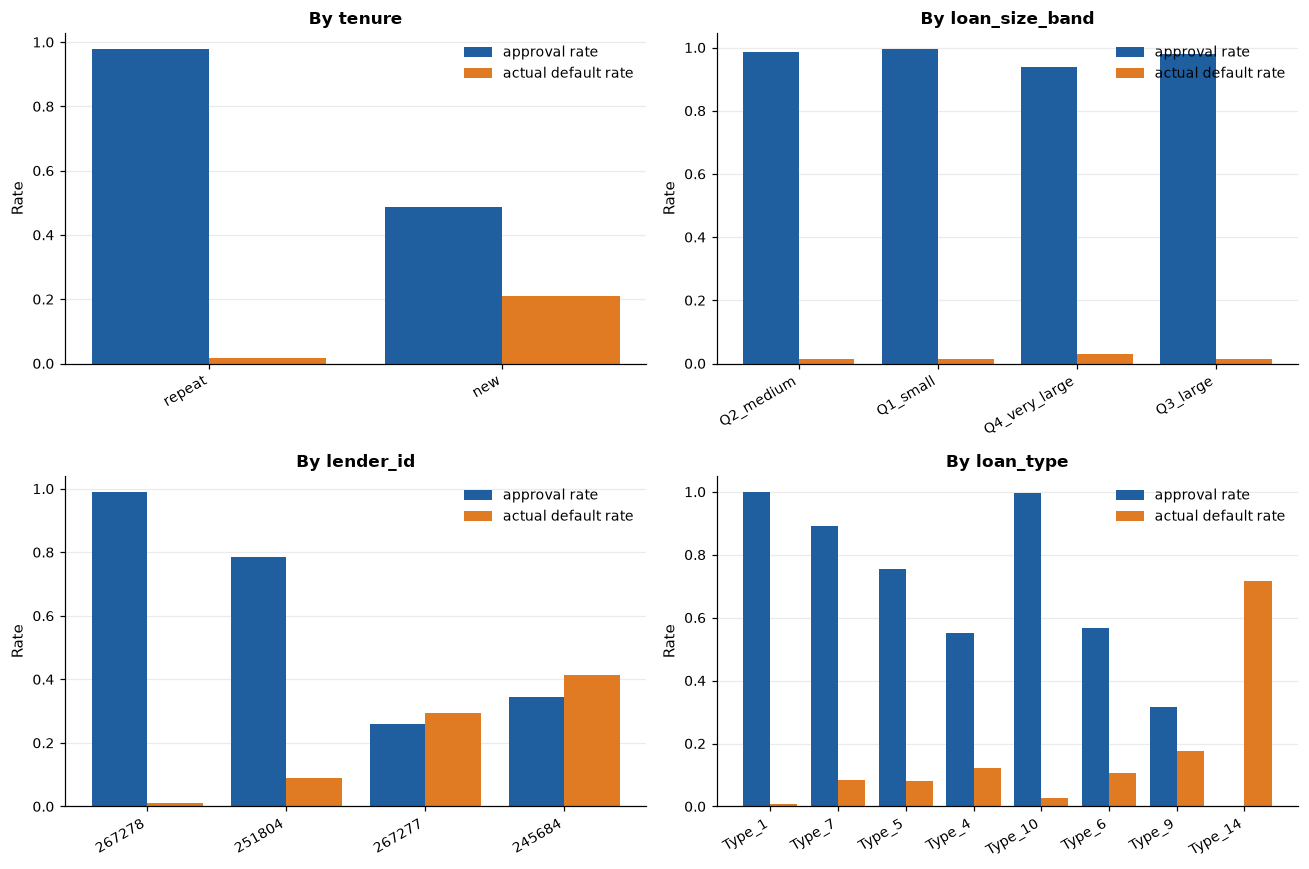

In [8]:
fair = oof["logreg"].assign(y_pred=oof["logreg"]["y_cal"]).merge(train[["ID", "log_amount_usd"]], on="ID")
fair["loan_size_band"] = add_loan_size_band(fair)
fair["tenure"] = np.where(fair["is_new_borrower"] == 1, "new", "repeat")

cols = ["group", "n", "selection_rate", "actual_default_rate", "mean_pred_prob", "pr_auc", "f1", "fpr", "disparate_impact_ratio"]
tables = {c: disaggregated_evaluation(fair, c, threshold=THR) for c in ["tenure", "loan_size_band", "lender_id", "loan_type"]}
for c, t in tables.items():
    print(f"--- {c}")
    display(t[cols].head(8).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (c, t) in zip(axes.ravel(), tables.items()):
    plot_group_selection_rates(t.head(8), ax=ax)
plt.tight_layout()
plt.show()

In [9]:
# Country: Test predictions from the scorer (unlabelled, so selection rate and mean score only)
disaggregated_evaluation(sc.rename(columns={"probability_of_default": "y_pred"}), "country_id", threshold=THR)[
    ["group", "n", "selection_rate", "mean_pred_prob", "disparate_impact_ratio"]].round(3)

,group,n,selection_rate,mean_pred_prob,disparate_impact_ratio
0,Kenya,15069,0.977,0.017,1.000
1,Ghana,3525,0.863,0.081,0.883


**Reading.**
- **First-time borrowers: the largest gap.** They are approved 48.7% of the time, against 97.9% for repeat borrowers, a ratio of 0.50. The gap tracks real risk (21% default against 1.7%). It falls entirely on people with no history, who Findex shows are already excluded (§4). Without the starter loan this would be the shipped outcome. §3.4 adds the starter loan and costs it.
- **Loan size: not regressive.** The smallest loans are approved most (99.6%) and the largest least (93.9%), a ratio of 0.94, in line with default rates of 1.3% against 2.9%.
- **Lender: one gap below 0.8 that does not follow risk alone.**
  - Lender 267278 (94% of rows, 1.2% default) is approved 99% of the time, and lender 251804 78% (ratio 0.79, 8.9% default).
  - The two small lenders, 267277 and 245684, are approved only 26% and 35% of the time. Their default rates are 30% and 42%, so most of that gap is real risk.
  - A borrower does not choose their funding lender, which is why the borrower message rewords the lender reason (`borrower_reasons`, `docs/audit/decline_explanation.md`).
- **Product: gaps follow risk.**
  - Type_1 is approved 100% of the time and Type_14 0%, with a 72% default rate.
  - Type_9, Type_4 and Type_6 are approved 32–57% of the time, with 11–18% default.
- **Country.** On Test, Kenyan applications pass the risk threshold 97.7% of the time and Ghanaian ones 86.3% of the time (ratio 0.88). After the limit rule (§2.3), however, no Ghanaian gets the amount requested.

### 3.2 Sensitivity to the cost matrix

The threshold is a business choice, so the fairness picture has to be read against it. The table compares the shipped cedi threshold (3 future loans lost, D-26) with the earlier KES matrix (D-19), Henry's cedi matrix with 1 future loan (D-22), and a 6-loan version.

In [10]:
sens = {f"KES, 1 loan (D-19) {THR_KES:.3f}": THR_KES, f"cedis, 1 loan (D-22) {THR_1LOAN:.3f}": THR_1LOAN,
        f"shipped: cedis, 3 loans {THR:.3f}": THR, f"cedis, 6 loans {THR_6LOANS:.3f}": THR_6LOANS}
pd.concat({name: disaggregated_evaluation(fair, "tenure", threshold=t).set_index("group")[["selection_rate", "disparate_impact_ratio"]]
           for name, t in sens.items()}, axis=1).round(3)

KES, 1 loan (D-19) 0.019                        cedis, 1 loan (D-22) 0.036                        shipped: cedis, 3 loans 0.101                         \
                 selection_rate disparate_impact_ratio             selection_rate disparate_impact_ratio                selection_rate disparate_impact_ratio   
group                                                                                                                                                           
repeat                    0.835                    1.0                      0.917                  1.000                         0.979                  1.000   
new                       0.000                    0.0                      0.120                  0.131                         0.487                  0.497   

       cedis, 6 loans 0.183                         
             selection_rate disparate_impact_ratio  
group                                               
repeat                0.993                  1.000  
new                   0.702                  0.707

**Reading.** First-time approval depends almost entirely on the cost matrix:

| Cost matrix | Threshold | First-time approval | Ratio |
| --- | --- | --- | --- |
| Old KES (D-19) | 0.019 | 0% | 0.00 |
| Cedis, 1 future loan (D-22) | 0.036 | 12% | 0.13 |
| **Cedis, 3 future loans (shipped, D-26)** | **0.10** | **49%** | **0.50** |
| Cedis, 6 future loans | 0.18 | 70% | 0.71 |

The model is the same in every row. What changes is how much NkwaPay believes it loses when it turns a good borrower away. That is why D-26 had to be a team decision: it is a fairness choice as much as a business one. Three future loans assumes that about 1 in 4 declined good borrowers leave for good, taking the 8 later loans a typical customer would have taken with them. It is still an assumption, and the pilot (§2.4) should measure it.

### 3.3 Proxy analysis: which inputs stand in for country or tenure? (fixes draft problem 3)

We have no gender, age or region in the loan data, so the protected-attribute question has to be asked indirectly. Do any model inputs *identify* a group we might treat unfairly? Proxy strength = |AUC − 0.5| × 2 of each feature on its own: 0 means no information about the group, 1 means it identifies the group perfectly.

In [11]:
feats = C.NUM_FEATURES_T2 + C.CAT_FEATURES
gh_proxy = proxy_strength(df.assign(is_ghana=df["country_id"].eq("Ghana").astype(int)), "is_ghana", feats)
new_proxy = proxy_strength(train, "is_new_borrower", [f for f in feats if f != "is_new_borrower"])
pd.concat({"proxy for Ghana": gh_proxy.head(6).reset_index(drop=True),
           "proxy for first-time borrower": new_proxy.head(6).reset_index(drop=True)}, axis=1).round(3)

proxy for Ghana                       proxy for first-time borrower                      
                feature    auc proxy_strength                       feature    auc proxy_strength
0             lender_id  1.000          1.000                  n_past_loans  0.043          0.914
1             loan_type  1.000          1.000               n_past_labelled  0.084          0.832
2        log_amount_usd  0.948          0.896                     loan_type  0.731          0.463
3       n_past_labelled  0.087          0.825                     lender_id  0.654          0.308
4     n_lenders_on_loan  0.867          0.735                    disb_month  0.381          0.239
5  days_since_last_loan  0.785          0.570                      duration  0.619          0.238

**Reading.**
- **For country:** lender and loan type identify Ghana perfectly (1.0), and the USD amount nearly so (0.90). Even if `country_id` were removed, the model would know which country an application comes from. Fairness across countries therefore has to be tested on outcomes, not assumed from the inputs.
- **For tenure:** `n_past_loans` (0.91) and `n_past_labelled` (0.83) are near-proxies for being new, as expected, and loan type is a moderate one (0.46). Dropping `is_new_borrower` would not remove the tenure gap, because the history fields carry the same information.

So "drop the proxy" is not a viable mitigation here. That leads to a decision-level fix.

### 3.4 Mitigation with its cost (#50; fixes draft problem 2)

**Option tested: a starter loan for first-time borrowers just above the threshold.** Repeat borrowers keep the shipped rule. First-time borrowers whose calibrated risk is between the threshold and a cut-off (`starter_up_to`) are offered a loan at a fraction `size` of the request, instead of a decline. Costs use the shipped cedi cost matrix:
- an approved defaulter loses `size × principal × (1 − recovery) + collection cost`;
- a declined good borrower loses `C_FP`;
- a good borrower given a starter loan loses the fee on the part that was not lent.

In [12]:
nb = fair[fair["is_new_borrower"] == 1]
REPEAT_APPROVAL = float(np.mean(fair.loc[fair["is_new_borrower"] == 0, "y_pred"] <= THR))

def starter_option(t_max, size, cm=cost):
    """First-time borrowers: full loan at p <= THR, a loan of `size` x request at THR < p <= t_max, else decline."""
    y = nb["y_true"].astype(int)
    full = nb["y_pred"] <= THR
    start = (nb["y_pred"] > THR) & (nb["y_pred"] <= t_max)
    c_fn_start = size * cm["principal"] * (1 - cm["recovery_rate"]) + cm["collection_cost"]
    total = ((full & (y == 1)).sum() * cm["c_fn"] + (start & (y == 1)).sum() * c_fn_start
             + (~(full | start) & (y == 0)).sum() * cm["c_fp"] + (start & (y == 0)).sum() * (1 - size) * cm["c_fp"])
    approved = full | start
    return {"starter_up_to": t_max, "size": size, "approval_new": approved.mean(), "ratio_vs_repeat": approved.mean() / REPEAT_APPROVAL,
            "starter_loans": int(start.sum()), "defaulters_in_band": int((start & (y == 1)).sum()), "total_cost_GHS": total}

options = [(THR, 1.0)] + [(t, s) for t in (0.15, 0.20, 0.25, 0.30, 0.50) for s in (1.0, 0.5, 0.25)]
mit = pd.DataFrame([starter_option(t, s) for t, s in options])
mit["extra_cost_GHS"] = mit["total_cost_GHS"] - mit["total_cost_GHS"].iloc[0]
mit["extra_per_new_applicant"] = mit["extra_cost_GHS"] / len(nb)
mit.round(3)

,starter_up_to,size,approval_new,ratio_vs_repeat,starter_loans,defaulters_in_band,total_cost_GHS,extra_cost_GHS,extra_per_new_applicant
0,0.101,1.00,0.487,0.497,0,0,89456.240,0.000,0.000
1,0.150,1.00,0.621,0.634,76,17,114594.420,25138.180,44.335
2,0.150,0.50,0.621,0.634,76,17,102151.130,12694.890,22.390
3,0.150,0.25,0.621,0.634,76,17,95929.485,6473.245,11.417
4,0.200,1.00,0.734,0.749,140,29,129541.860,40085.620,70.698
5,0.200,0.50,0.734,0.749,140,29,109713.650,20257.410,35.727
6,0.200,0.25,0.734,0.749,140,29,99799.545,10343.305,18.242
7,0.250,1.00,0.783,0.800,168,32,130036.560,40580.320,71.570
8,0.250,0.50,0.783,0.800,168,32,109983.200,20526.960,36.203
9,0.250,0.25,0.783,0.800,168,32,99956.520,10500.280,18.519


In [13]:
# Before / after with the scorer's own rule (`decide`): before = threshold only, after = with the configured starter loan
dec_before, _ = decide(fair["y_pred"], 1.0, np.inf, fair["is_new_borrower"], THR)
dec_after, _ = decide(fair["y_pred"], 1.0, np.inf, fair["is_new_borrower"], THR, STARTER)
fair["approve_before"], fair["approve_after"] = dec_before != "decline", dec_after != "decline"
chosen = mit.query("starter_up_to == @STARTER['max_probability'] and size == @STARTER['share_of_request']")
rows = []
for label, col in [("before", "approve_before"), ("after", "approve_after")]:
    money = decision_cost_by_group(fair, "tenure", col, c_fp=cost["c_fp"], c_fn=cost["c_fn"]).set_index("group")
    for g, gdf in fair.groupby("tenure"):
        thr_g = STARTER["max_probability"] if (label == "after" and g == "new") else THR
        m = classification_metrics(gdf["y_true"], gdf["y_pred"], threshold=thr_g)
        per_app = (chosen["total_cost_GHS"].iloc[0] / len(nb) if (label == "after" and g == "new")
                   else money.loc[g, "cost_per_applicant"])
        rows.append({"when": label, "group": g, "approval": gdf[col].mean(), "pr_auc": m["pr_auc"], "f1": m["f1"],
                     "defaults_approved": money.loc[g, "defaults_approved"], "expected_cost_per_applicant_GHS": per_app})
pd.DataFrame(rows).round(3)

,when,group,approval,pr_auc,f1,defaults_approved,expected_cost_per_applicant_GHS
0,before,new,0.487,0.569,0.502,16,157.771
1,before,repeat,0.979,0.127,0.177,912,37.148
2,after,new,0.813,0.569,0.622,49,175.469
3,after,repeat,0.979,0.127,0.177,912,37.148


**Reading and recommendation.**
- **Shipped threshold alone.** 48.7% of first-time borrowers are approved (ratio 0.50). Their expected cost is GHS 89.5k across these 567 people.
- **The chosen policy (D-24, now in the scorer): a starter loan of 25% of the request, up to p = 0.30.**
  - First-time approval rises to **81.3% (ratio 0.83, above 0.8)**.
  - It costs an extra **GHS 10.0k**, about **GHS 18 per first-time applicant**.
  - 185 people get a starter loan, and 33 of them default (18%). Because each loan is a quarter of the size, the loss stays small.
  - Approving the same band at full size would cost GHS 38.7k extra.
- **Why 0.30 and not 0.25.** At 25% size, the 0.30 cut-off costs slightly *less* than 0.25 (10.0k against 10.5k). The extra good borrowers it admits pay partial fees that outweigh its one extra defaulter.
- **Why not go further.** Going on to 0.50 raises the ratio only to 0.88, but it nearly doubles the cost (19.0k) and lets in 16 more defaulters.
- **Before and after:**
  - F1 for first-time borrowers rises from 0.50 to 0.62, measured at their own threshold.
  - PR-AUC does not change, because the policy changes decisions, not the ranking.
  - Repeat borrowers are untouched.
- **What stays open.** The starter loan is costed with the brief-style assumptions above. The pilot should measure the real repayment rate of starter loans.

## 4. Who in Ghana cannot access credit today? (#28)

World Bank Global Findex 2021, Ghana, survey-weighted (`wgt`). This describes the **adult population**, not our applicants.

In [14]:
findex_access(pd.read_csv(C.FINDEX_CSV)).round(1)

,group,n,has_account,mobile_money,borrowed_formally,borrowed_any
0,All adults,1000,68.2,59.7,7.2,52.2
1,Women,465,62.6,55.0,5.6,47.9
2,Men,535,74.2,64.6,9.0,56.7
3,Rural,360,56.5,47.9,6.6,52.0
4,Urban,640,76.1,67.6,7.7,52.4
5,Poorest 40%,309,54.7,46.4,4.9,52.1
6,Richest 60%,691,77.2,68.5,8.8,52.3
7,Primary or less,295,51.6,42.9,4.7,50.3
8,Tertiary,64,98.3,90.7,32.0,62.0


**Reading.** Only 7.2% of Ghanaian adults borrowed from a formal institution. The rate is lower for women (5.6% against 9.0% for men), for rural adults (6.6% against 7.7% urban), for the poorest 40% (4.9% against 8.8%) and for adults with primary education or less (4.7%). It reaches 32% for the tertiary-educated. About 40% of adults have no mobile-money account, so they cannot even reach a digital lender.

**Does our model narrow or widen the gap?** On its own it widens it. It learned only from people lenders already approved (D-14), and under the old KES cost matrix it declined every first-time borrower. The people with no history are, by Findex, disproportionately women, rural and poorer adults. With the cedi cost matrix and the starter loan, 81% of first-time borrowers get a way in (§3.4). That narrows the gap for people who can apply, but it does nothing for the 40% with no mobile-money account. That part needs a product decision, not a model.

## 5. Summary for the report

| Question | Answer | Evidence |
| --- | --- | --- |
| Best ranking model | Random Forest (PR-AUC 0.203 by customer), but the ensembles' edge vanishes by time (ROC-AUC ≈ 0.6 for all) | §1 |
| Shipped model | Logistic regression, Platt-calibrated, threshold 0.10 from the cedi cost matrix. It approves 97.5% of Kenyan applicants and catches 26% of defaulters | §1.1 |
| Is Ghana like Kenya? | No. Domain AUC 0.985 even without the label-history artefact; importance weighting is unusable (ESS share 0.04) | §2.2 |
| What happens to Ghana | No full approvals: 86% are limited to about 15% of the request and 14% are declined. The probabilities depend on an unobservable history field | §2.3 |
| Trust in Ghana needs | A capped pilot of ~3,500 loans over ~3 months, history encoded as unknown, Ghana recalibration, monitoring triggers | §2.4 |
| Biggest fairness gap | First-time borrowers: 48.7% approved against 97.9% (ratio 0.50); real default rate 21% | §3.1 |
| What drives it | The cost matrix: first-time approval ranges from 0% to 70% across defensible assumptions, with the same model | §3.2 |
| Proxies | Lender and product identify Ghana perfectly; the history fields identify first-time borrowers | §3.3 |
| Mitigation (in the scorer) | A 25% starter loan up to p = 0.30: 49% → 81% approved (ratio 0.83) for about GHS 18 per first-time applicant | §3.4 |
| Access | Formal borrowing is 7.2%, lower for women, rural, poor and less-educated adults; the starter loan narrows the gap for people who can apply | §4 |